# Lab 7 : Principal Component Analysis (PCA)
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Aim** : Implement PCA on a simple dataset, step by step from scratch with NumPy, verify it against scikit-learn, and use it to reduce 4 dimensions to 2.

**Dataset** : Iris (150 samples × 4 numeric features, 3 species).

## Theory
PCA finds new axes (**principal components**) along which the data varies the most. The components are orthogonal and uncorrelated, and are ordered by how much variance they capture, so keeping only the first *k* reduces dimensions while losing as little information as possible.

**Algorithm**
1. **Standardise** each feature (mean 0, std 1) so that features with large units do not dominate.
2. Compute the **covariance matrix** C = (1 / (n-1)) · XᵀX of the standardised data.
3. Find the **eigenvalues and eigenvectors** of C : C·v = λ·v.
4. **Sort** eigenvectors by eigenvalue, largest first. Eigenvector = direction of a PC, eigenvalue = variance along it.
5. **Explained variance ratio** of PCᵢ = λᵢ / Σλ. Choose k components (e.g. enough to cover ~95% of the variance).
6. **Project** : Z = X · W, where W holds the top-k eigenvectors as columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEED = 77                     # last two digits of roll number
np.random.seed(SEED)
pd.set_option("display.precision", 4)

In [2]:
iris = load_iris()
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = pd.DataFrame(iris.data, columns=features)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

X = df[features].values
y = iris.target
print("Shape :", X.shape)
df.head()

Shape : (150, 4)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 1 : Standardise the data

In [3]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)     # z-score

print("Means after standardising :", X_std.mean(axis=0).round(4))
print("Stds  after standardising :", X_std.std(axis=0).round(4))

Means after standardising : [-0. -0. -0. -0.]
Stds  after standardising : [1. 1. 1. 1.]


## Step 2 : Covariance matrix of the standardised data

In [4]:
n = X_std.shape[0]
cov = (X_std.T @ X_std) / (n - 1)
pd.DataFrame(cov, index=features, columns=features)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.0067,-0.1184,0.8776,0.8234
sepal_width,-0.1184,1.0067,-0.4313,-0.3686
petal_length,0.8776,-0.4313,1.0067,0.9693
petal_width,0.8234,-0.3686,0.9693,1.0067


## Step 3 : Eigenvalues and eigenvectors

In [5]:
eig_vals, eig_vecs = np.linalg.eigh(cov)      # eigh : for symmetric matrices

# Step 4 : sort largest → smallest
order = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[order]
eig_vecs = eig_vecs[:, order]

print("Eigenvalues :", eig_vals.round(4))
pd.DataFrame(eig_vecs, index=features, columns=[f"PC{i+1}" for i in range(4)])

Eigenvalues : [2.9381 0.9202 0.1477 0.0209]


,PC1,PC2,PC3,PC4
sepal_length,-0.5211,0.3774,0.7196,0.2613
sepal_width,0.2693,0.9233,-0.2444,-0.1235
petal_length,-0.5804,0.0245,-0.1421,-0.8014
petal_width,-0.5649,0.0669,-0.6343,0.5236


## Step 5 : Explained variance and choosing k

In [6]:
explained = eig_vals / eig_vals.sum()
cumulative = np.cumsum(explained)

pd.DataFrame({"Eigenvalue": eig_vals,
              "Explained variance %": explained * 100,
              "Cumulative %": cumulative * 100},
             index=[f"PC{i+1}" for i in range(4)])

,Eigenvalue,Explained variance %,Cumulative %
PC1,2.9381,72.9624,72.9624
PC2,0.9202,22.8508,95.8132
PC3,0.1477,3.6689,99.4821
PC4,0.0209,0.5179,100.0000


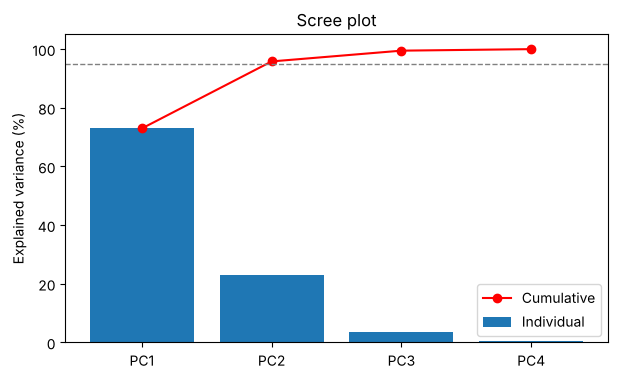

In [7]:
pcs = [f"PC{i+1}" for i in range(4)]
plt.figure(figsize=(7, 4))
plt.bar(pcs, explained * 100, label="Individual")
plt.plot(pcs, cumulative * 100, "o-", color="red", label="Cumulative")
plt.axhline(95, ls="--", color="gray", lw=1)
plt.ylabel("Explained variance (%)")
plt.title("Scree plot")
plt.legend()
plt.show()

PC1 and PC2 together explain about **95.8%** of the variance, so **k = 2** is enough : 4 features → 2 with very little information lost.

## Step 6 : Project the data onto the top 2 components

In [8]:
k = 2
W = eig_vecs[:, :k]          # 4 × 2 projection matrix
Z = X_std @ W                # 150 × 2

pca_df = pd.DataFrame(Z, columns=["PC1", "PC2"])
pca_df["species"] = df["species"]
pca_df.head()

,PC1,PC2,species
0,2.2647,0.4800,setosa
1,2.0810,-0.6741,setosa
2,2.3642,-0.3419,setosa
3,2.2994,-0.5974,setosa
4,2.3898,0.6468,setosa


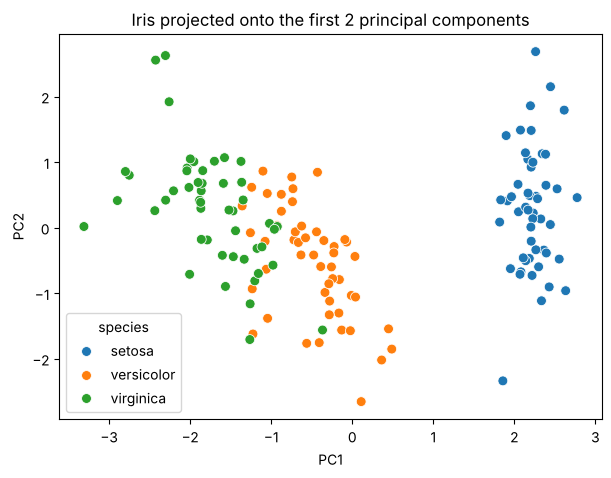

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species", s=50)
plt.title("Iris projected onto the first 2 principal components")
plt.show()

## Verification with scikit-learn
Eigenvectors are unique only up to sign, so sklearn's components may be flipped (×-1). We compare absolute values.

In [10]:
X_sk = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
Z_sk = pca.fit_transform(X_sk)

print("sklearn explained variance ratio :", pca.explained_variance_ratio_.round(4))
print("manual  explained variance ratio :", explained[:2].round(4))
print("Projections match (up to sign)   :", np.allclose(np.abs(Z), np.abs(Z_sk)))

sklearn explained variance ratio : [0.7296 0.2285]
manual  explained variance ratio : [0.7296 0.2285]
Projections match (up to sign)   : True


## Interpreting the components (loadings)

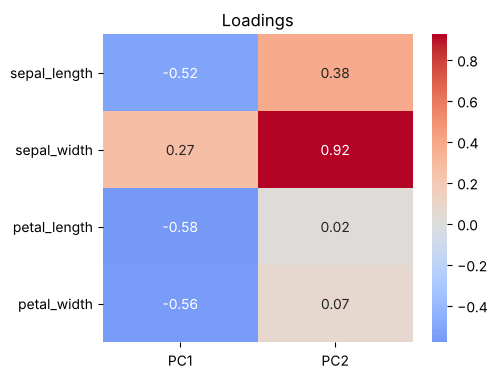

In [11]:
loadings = pd.DataFrame(W, index=features, columns=["PC1", "PC2"])
plt.figure(figsize=(5, 4))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings")
plt.show()

* **PC1** has large weights on petal length, petal width and sepal length : it is a "flower size" axis, and it alone separates setosa from the other two species.
* **PC2** is dominated by sepal width.

## Result & Conclusion
* PCA was implemented from scratch (standardise → covariance matrix → eigen-decomposition → sort → project) and matched scikit-learn's output exactly (up to sign).
* The first two principal components retain ~95.8% of the variance, reducing Iris from 4D to 2D.
* In the 2D projection the three species form clear groups, so PCA is useful both for visualisation and as a pre-processing step before classification.